###Install Dependencies

In [1]:
!pip -q install scikit-image scipy networkx

###Connect Google Drive

In [2]:
from google.colab import drive
drive.mount("/content/drive")

import sys

sys.path.insert(
    0,
    "/content/drive/MyDrive/ArteryAI/src"
)

from config import *

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import json

from pathlib import Path
from tqdm.auto import tqdm

from skimage.morphology import skeletonize
from scipy.ndimage import distance_transform_edt

import networkx as nx

print("Project connected successfully!")
print("Project root:", ROOT)
print("Device setup ready!")

Mounted at /content/drive
Project connected successfully!
Project root: /content/drive/MyDrive/ArteryAI
Device setup ready!


###Load Previous Segmentation Masks

In [3]:
OUT = M2 / "outputs"

MASK_DIR = OUT / "masks"

CENTERLINE_DIR = OUT / "centerlines"

VESSEL_DIR = OUT / "vessel_analysis"

CENTERLINE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

VESSEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

mask_files = sorted(
    MASK_DIR.glob("*_mask.png")
)

print("Total masks found:", len(mask_files))

print("\nFirst 10 mask files:")

for f in mask_files[:10]:
    print(f.name)

assert len(mask_files) > 0, (
    "No segmentation masks found!"
)

print("\nSegmentation masks loaded successfully!")

Total masks found: 300

First 10 mask files:
100_mask.png
101_mask.png
102_mask.png
103_mask.png
104_mask.png
105_mask.png
106_mask.png
107_mask.png
108_mask.png
109_mask.png

Segmentation masks loaded successfully!


###Visualize a Sample Mask

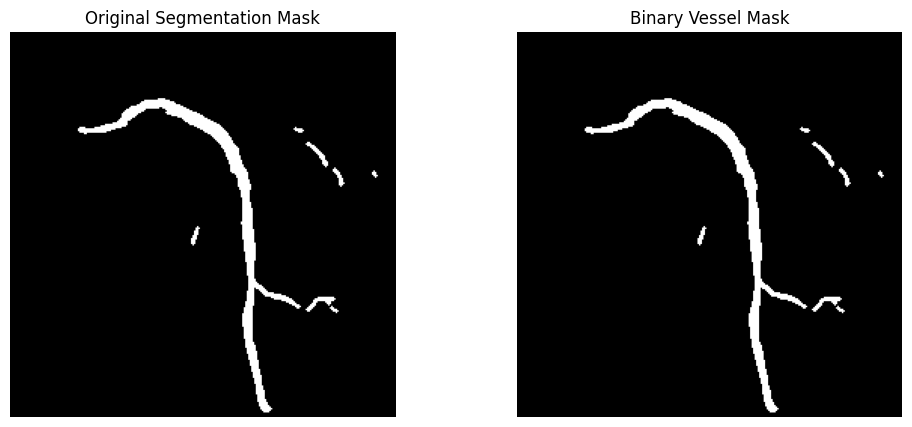

Image ID: 100_mask
Mask shape: (256, 256)
Foreground pixels: 2309


In [4]:
sample_path = mask_files[0]

sample_mask = cv2.imread(
    str(sample_path),
    cv2.IMREAD_GRAYSCALE
)

binary_mask = sample_mask > 0

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(sample_mask, cmap="gray")
plt.title("Original Segmentation Mask")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary_mask, cmap="gray")
plt.title("Binary Vessel Mask")
plt.axis("off")

plt.show()

print("Image ID:", sample_path.stem)
print("Mask shape:", binary_mask.shape)
print("Foreground pixels:", binary_mask.sum())

###Vessel Skeletonization & Centerline Extraction

In [5]:
from skimage.morphology import skeletonize
from scipy.ndimage import distance_transform_edt
import numpy as np
import cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

skeleton_files = []

for mask_path in tqdm(mask_files):

    # Load binary mask
    mask = cv2.imread(
        str(mask_path),
        cv2.IMREAD_GRAYSCALE
    )

    binary = mask > 0

    # Skeletonization
    skeleton = skeletonize(binary)

    # Save centerline
    skeleton_img = (
        skeleton.astype(np.uint8) * 255
    )

    output_path = (
        CENTERLINE_DIR /
        f"{mask_path.stem}_centerline.png"
    )

    cv2.imwrite(
        str(output_path),
        skeleton_img
    )

    skeleton_files.append(output_path)

print("Skeletonization completed!")
print("Total centerlines:", len(skeleton_files))

  0%|          | 0/300 [00:00<?, ?it/s]

Skeletonization completed!
Total centerlines: 300


###Visualize Vessel Centerline

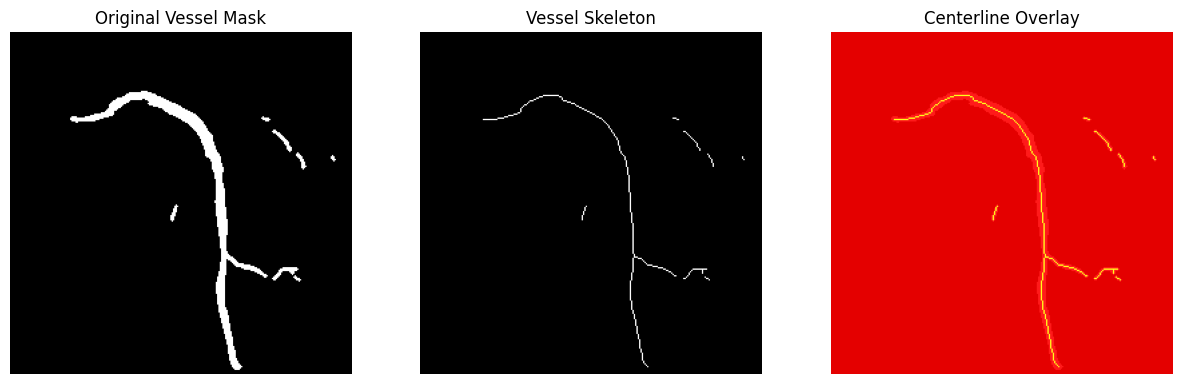

In [6]:
sample_mask = cv2.imread(
    str(mask_files[0]),
    cv2.IMREAD_GRAYSCALE
)

sample_skeleton = cv2.imread(
    str(skeleton_files[0]),
    cv2.IMREAD_GRAYSCALE
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(sample_mask, cmap="gray")
plt.title("Original Vessel Mask")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(sample_skeleton, cmap="gray")
plt.title("Vessel Skeleton")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(sample_mask, cmap="gray")
plt.imshow(
    sample_skeleton > 0,
    cmap="autumn",
    alpha=0.9
)
plt.title("Centerline Overlay")
plt.axis("off")

plt.show()

###Branching Point & Endpoint Detection

In [7]:
from scipy.ndimage import convolve, label
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# 8-neighbour connectivity kernel
kernel = np.array([
    [1, 1, 1],
    [1, 0, 1],
    [1, 1, 1]
], dtype=np.uint8)

branch_records = []

for mask_path, skeleton_path in tqdm(
    zip(mask_files, skeleton_files),
    total=len(mask_files),
    desc="Detecting vessel branches"
):

    skeleton_img = cv2.imread(
        str(skeleton_path),
        cv2.IMREAD_GRAYSCALE
    )

    skeleton = skeleton_img > 0

    # Count neighbouring skeleton pixels
    neighbours = convolve(
        skeleton.astype(np.uint8),
        kernel,
        mode="constant"
    )

    # Identify endpoints and branch candidates
    endpoints = skeleton & (neighbours == 1)

    branch_candidates = (
        skeleton & (neighbours >= 3)
    )

    # Group adjacent branch candidates
    branch_labels, branch_count = label(
        branch_candidates,
        structure=np.ones((3, 3))
    )

    # Calculate representative branch coordinates
    branch_coordinates = []

    for component_id in range(
        1, branch_count + 1
    ):

        coords = np.argwhere(
            branch_labels == component_id
        )

        center = coords.mean(axis=0)

        branch_coordinates.append(center)

    branch_records.append({

        "image_id": mask_path.stem,

        "skeleton_pixels": int(
            skeleton.sum()
        ),

        "endpoint_count": int(
            endpoints.sum()
        ),

        "branch_cluster_count": int(
            branch_count
        ),

        "branch_coordinates": str(
            branch_coordinates
        )
    })

branch_df = pd.DataFrame(branch_records)

branch_df.to_csv(
    VESSEL_DIR / "branch_analysis.csv",
    index=False
)

print("Branch detection completed!")

display(branch_df.head())

print(
    "Total endpoints:",
    branch_df["endpoint_count"].sum()
)

print(
    "Total branch clusters:",
    branch_df["branch_cluster_count"].sum()
)

Detecting vessel branches:   0%|          | 0/300 [00:00<?, ?it/s]

Branch detection completed!


,image_id,skeleton_pixels,endpoint_count,branch_cluster_count,branch_coordinates
0,100_mask,380,18,2,"[array([167.66666667, 160.33333333]), array([1..."
1,101_mask,372,17,4,"[array([ 79.75, 158. ]), array([111.66666667,..."
2,102_mask,393,9,3,"[array([43.25, 77. ]), array([45.25, 62. ]),..."
3,103_mask,400,8,2,"[array([48., 77.]), array([102. , 142.25])]"
4,104_mask,324,15,1,"[array([ 72.25, 125. ])]"


Total endpoints: 3383
Total branch clusters: 788


###Visualize Branching Points

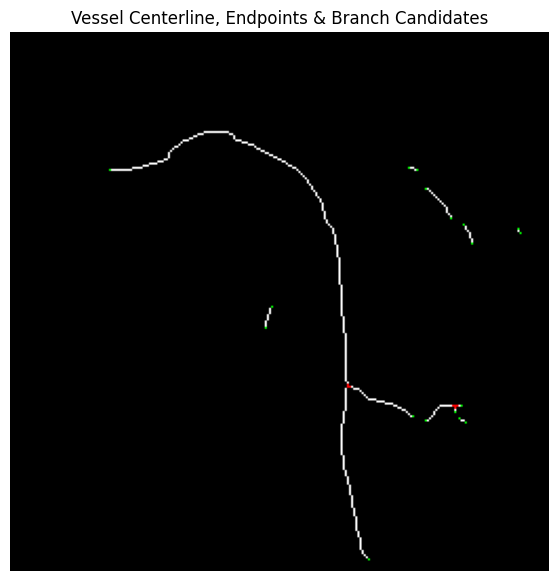

Endpoints: 18
Branch clusters: 2


In [8]:
sample_skeleton = cv2.imread(
    str(skeleton_files[0]),
    cv2.IMREAD_GRAYSCALE
) > 0

neighbors = convolve(
    sample_skeleton.astype(np.uint8),
    kernel,
    mode="constant"
)

endpoints = (
    sample_skeleton & (neighbors == 1)
)

branch_candidates = (
    sample_skeleton & (neighbors >= 3)
)

branch_labels, branch_count = label(
    branch_candidates,
    structure=np.ones((3, 3))
)

# RGB visualization
visual = np.zeros(
    (*sample_skeleton.shape, 3),
    dtype=np.uint8
)

# Centerline = white
visual[sample_skeleton] = [255, 255, 255]

# Endpoints = green
visual[endpoints] = [0, 255, 0]

# Branch candidates = red
visual[branch_candidates] = [255, 0, 0]

plt.figure(figsize=(9, 7))

plt.imshow(visual)

plt.title(
    "Vessel Centerline, Endpoints & Branch Candidates"
)

plt.axis("off")
plt.show()

print("Endpoints:", endpoints.sum())
print("Branch clusters:", branch_count)

###Corrected Centerline Overlay

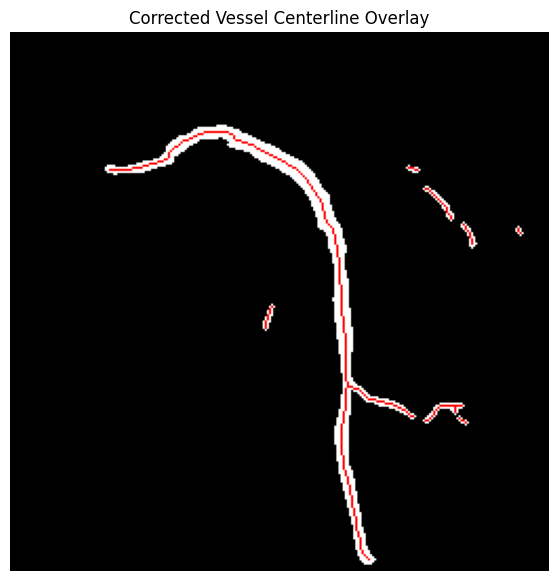

In [9]:
mask = cv2.imread(
    str(mask_files[0]),
    0
) > 0

skeleton = cv2.imread(
    str(skeleton_files[0]),
    0
) > 0

overlay = np.zeros(
    (*mask.shape, 3),
    dtype=np.uint8
)

overlay[mask] = [255, 255, 255]
overlay[skeleton] = [255, 0, 0]

plt.figure(figsize=(7, 7))
plt.imshow(overlay)
plt.title("Corrected Vessel Centerline Overlay")
plt.axis("off")
plt.show()

###Vessel Measurement Engine

In [10]:
from scipy.ndimage import distance_transform_edt, label
import numpy as np
import pandas as pd
import cv2
import math
from tqdm.auto import tqdm

measurement_records = []

for mask_path, skeleton_path in tqdm(
    zip(mask_files, skeleton_files),
    total=len(mask_files),
    desc="Measuring vessels"
):

    mask = cv2.imread(
        str(mask_path), 0
    ) > 0

    skeleton = cv2.imread(
        str(skeleton_path), 0
    ) > 0

    # 1. Vessel length using 8-connected edges
    offsets = [
        (0, 1, 1.0),
        (1, -1, math.sqrt(2)),
        (1, 0, 1.0),
        (1, 1, math.sqrt(2))
    ]

    vessel_length = 0.0

    for dy, dx, weight in offsets:

        shifted = np.roll(
            skeleton, (dy, dx), axis=(0, 1)
        )

        # Avoid wraparound
        if dy == 1:
            shifted[0, :] = False
        if dx == 1:
            shifted[:, 0] = False
        if dx == -1:
            shifted[:, -1] = False

        vessel_length += (
            np.logical_and(
                skeleton, shifted
            ).sum() * weight
        )

    # 2. Diameter using Euclidean distance transform
    distance_map = distance_transform_edt(mask)

    diameters = (
        2 * distance_map[skeleton]
    )

    if len(diameters) > 0:
        mean_diameter = diameters.mean()
        min_diameter = diameters.min()
        max_diameter = diameters.max()
        diameter_std = diameters.std()
    else:
        mean_diameter = 0
        min_diameter = 0
        max_diameter = 0
        diameter_std = 0

    # 3. Cross-sectional area proxy
    vessel_area = int(mask.sum())

    # 4. Connected components
    components, component_count = label(
        skeleton
    )

    # 5. Approximate tortuosity of largest component
    if component_count > 0:

        sizes = np.bincount(
            components.ravel()
        )
        sizes[0] = 0

        largest_id = sizes.argmax()

        largest = components == largest_id

        coords = np.argwhere(largest)

        endpoint_map = (
            largest &
            (cv2.filter2D(
                largest.astype(np.uint8),
                -1,
                np.ones((3, 3), dtype=np.uint8)
            ) - largest.astype(np.uint8) == 1)
        )

        endpoints_coords = np.argwhere(
            endpoint_map
        )

        component_length = 0.0

        for dy, dx, weight in offsets:

            shifted = np.roll(
                largest, (dy, dx), axis=(0, 1)
            )

            if dy == 1:
                shifted[0, :] = False
            if dx == 1:
                shifted[:, 0] = False
            if dx == -1:
                shifted[:, -1] = False

            component_length += (
                np.logical_and(
                    largest, shifted
                ).sum() * weight
            )

        if len(endpoints_coords) >= 2:

            distances = np.sqrt(
                ((endpoints_coords[:, None, :] -
                  endpoints_coords[None, :, :]) ** 2
                 ).sum(axis=2)
            )

            chord = distances.max()

            tortuosity = (
                component_length / chord
                if chord > 0 else np.nan
            )
        else:
            tortuosity = np.nan

    else:
        tortuosity = np.nan

    measurement_records.append({

        "image_id": mask_path.stem,

        "vessel_length_pixels": round(
            vessel_length, 2
        ),

        "mean_diameter_pixels": round(
            mean_diameter, 2
        ),

        "minimum_diameter_pixels": round(
            min_diameter, 2
        ),

        "maximum_diameter_pixels": round(
            max_diameter, 2
        ),

        "diameter_std": round(
            diameter_std, 2
        ),

        "cross_sectional_area_pixels": vessel_area,

        "connected_components": component_count,

        "tortuosity_proxy": (
            round(float(tortuosity), 3)
            if np.isfinite(tortuosity)
            else np.nan
        )
    })


measurement_df = pd.DataFrame(
    measurement_records
)

measurement_df.to_csv(
    VESSEL_DIR / "vessel_measurements.csv",
    index=False
)

print("Vessel measurement completed!")

display(measurement_df.head(10))

print("\nAverage vessel length:",
      measurement_df["vessel_length_pixels"].mean())

print("\nAverage vessel diameter:",
      measurement_df["mean_diameter_pixels"].mean())

print("\nMeasurement CSV saved!")

Measuring vessels:   0%|          | 0/300 [00:00<?, ?it/s]

Vessel measurement completed!


,image_id,vessel_length_pixels,mean_diameter_pixels,minimum_diameter_pixels,maximum_diameter_pixels,diameter_std,cross_sectional_area_pixels,connected_components,tortuosity_proxy
0,100_mask,423.88,5.79,2.00,10.00,2.01,2309,123,1.0
1,101_mask,426.92,5.92,2.00,11.66,2.25,2415,136,1.0
2,102_mask,439.56,5.88,2.00,13.42,1.88,2330,109,1.0
3,103_mask,471.97,5.40,2.83,11.31,1.62,2361,184,1.0
4,104_mask,374.75,4.36,2.00,13.42,1.71,1509,143,1.0
5,105_mask,370.81,5.08,2.00,8.25,1.41,1708,114,1.0
6,106_mask,635.24,5.33,2.00,14.56,1.98,3080,242,1.0
7,107_mask,471.99,7.70,2.83,12.17,2.07,3396,141,1.0
8,108_mask,814.54,6.62,2.00,11.31,2.15,5047,293,1.0
9,109_mask,358.84,5.66,2.00,8.94,1.65,1889,103,1.0



Average vessel length: 444.7422333333334

Average vessel diameter: 5.8124

Measurement CSV saved!


###Diameter Visualization

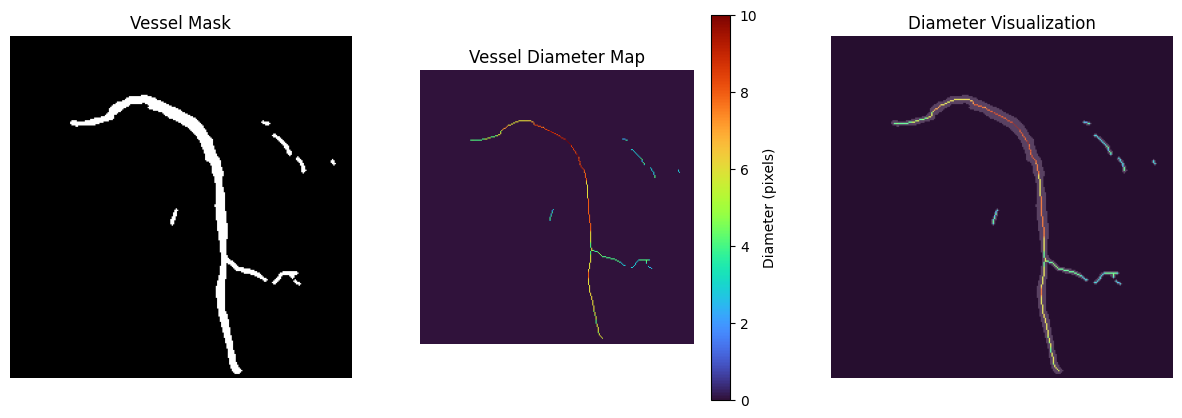

In [11]:
mask = cv2.imread(
    str(mask_files[0]), 0
) > 0

skeleton = cv2.imread(
    str(skeleton_files[0]), 0
) > 0

distance = distance_transform_edt(mask)

diameter_map = np.zeros_like(
    distance, dtype=np.float32
)

diameter_map[skeleton] = (
    2 * distance[skeleton]
)

import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(mask, cmap="gray")
plt.title("Vessel Mask")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(diameter_map, cmap="turbo")
plt.colorbar(label="Diameter (pixels)")
plt.title("Vessel Diameter Map")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(mask, cmap="gray")
plt.imshow(
    diameter_map,
    cmap="turbo",
    alpha=0.8
)
plt.title("Diameter Visualization")
plt.axis("off")

plt.show()

###Save Vessel Analysis Summary

In [12]:
summary = measurement_df.describe(
    include="all"
)

summary.to_csv(
    VESSEL_DIR / "vessel_analysis_summary.csv"
)

print("All vessel analysis reports saved!")
print("Output directory:", VESSEL_DIR)

All vessel analysis reports saved!
Output directory: /content/drive/MyDrive/ArteryAI/Milestone-2/outputs/vessel_analysis


###Corrected Continuity & Tortuosity Analysis

In [13]:
import networkx as nx
import numpy as np
import pandas as pd
import cv2

from scipy.ndimage import label, distance_transform_edt
from tqdm.auto import tqdm
from math import sqrt

results = []

structure = np.ones((3, 3), dtype=np.uint8)

for mask_path, skeleton_path in tqdm(
    zip(mask_files, skeleton_files),
    total=len(mask_files),
    desc="Vessel continuity analysis"
):

    mask = cv2.imread(str(mask_path), 0) > 0
    skeleton = cv2.imread(str(skeleton_path), 0) > 0

    # 1. 8-connected components
    labels, count = label(
        skeleton,
        structure=structure
    )

    sizes = np.bincount(labels.ravel())[1:]

    if len(sizes) == 0 or sizes.max() == 0:
        continue

    largest_id = np.argmax(sizes) + 1
    largest = labels == largest_id

    total_pixels = int(skeleton.sum())
    largest_pixels = int(largest.sum())

    continuity = (
        largest_pixels / total_pixels
        if total_pixels else 0
    )

    # 2. Diameter variation
    distance = distance_transform_edt(mask)
    diameter_values = 2 * distance[skeleton]

    if len(diameter_values):
        mean_d = diameter_values.mean()
        std_d = diameter_values.std()
        cv_d = std_d / mean_d if mean_d else 0
        q10 = np.percentile(diameter_values, 10)
        q90 = np.percentile(diameter_values, 90)
    else:
        mean_d = std_d = cv_d = q10 = q90 = 0

    # 3. Build graph for largest skeleton component
    coords = np.argwhere(largest)

    G = nx.Graph()

    for y, x in coords:
        G.add_node((int(y), int(x)))

    offsets = [
        (0, 1, 1.0),
        (1, -1, sqrt(2)),
        (1, 0, 1.0),
        (1, 1, sqrt(2))
    ]

    for y, x in coords:
        for dy, dx, weight in offsets:
            ny, nx_ = y + dy, x + dx

            if largest[ny, nx_]:
                G.add_edge(
                    (int(y), int(x)),
                    (int(ny), int(nx_)),
                    weight=weight
                )

    # 4. Endpoint-based tortuosity
    endpoints = [
        node for node in G.nodes()
        if G.degree(node) == 1
    ]

    tortuosity = np.nan
    geodesic_length = np.nan
    euclidean_length = np.nan

    if len(endpoints) >= 2:

        best_geodesic = 0

        for source in endpoints:
            distances = nx.single_source_dijkstra_path_length(
                G, source, weight="weight"
            )

            for target in endpoints:
                if target == source:
                    continue

                if target not in distances:
                    continue

                geo = distances[target]

                if geo > best_geodesic:
                    euclidean = sqrt(
                        (source[0] - target[0])**2 +
                        (source[1] - target[1])**2
                    )

                    if euclidean > 0:
                        best_geodesic = geo
                        geodesic_length = geo
                        euclidean_length = euclidean
                        tortuosity = geo / euclidean

    results.append({
        "image_id": mask_path.stem,
        "components_8_connected": count,
        "continuity_ratio": round(continuity, 4),
        "largest_component_pixels": largest_pixels,
        "total_skeleton_pixels": total_pixels,
        "mean_diameter": round(mean_d, 3),
        "diameter_variation": round(cv_d, 4),
        "diameter_q10": round(q10, 3),
        "diameter_q90": round(q90, 3),
        "tortuosity": (
            round(tortuosity, 4)
            if np.isfinite(tortuosity) else np.nan
        ),
        "geodesic_length": geodesic_length,
        "euclidean_length": euclidean_length
    })

continuity_df = pd.DataFrame(results)

continuity_df.to_csv(
    VESSEL_DIR / "continuity_tortuosity_analysis.csv",
    index=False
)

display(continuity_df.head(10))

print("Continuity and tortuosity analysis completed!")
print("Saved:", VESSEL_DIR)

Vessel continuity analysis:   0%|          | 0/300 [00:00<?, ?it/s]

,image_id,components_8_connected,continuity_ratio,largest_component_pixels,total_skeleton_pixels,mean_diameter,diameter_variation,diameter_q10,diameter_q90,tortuosity,geodesic_length,euclidean_length
0,100_mask,8,0.8132,309,380,5.787,0.3473,2.828,8.246,1.3830,307.237590,222.157602
1,101_mask,8,0.5027,187,372,5.922,0.3802,4.000,10.000,1.8982,200.681241,105.721332
2,102_mask,3,0.9771,384,393,5.878,0.3206,4.000,8.944,1.6190,264.852814,163.590953
3,103_mask,5,0.9375,375,400,5.398,0.2993,4.000,8.000,1.3396,301.320851,224.931101
4,104_mask,8,0.5833,189,324,4.359,0.3914,2.828,6.000,5.3719,189.923882,35.355339
5,105_mask,4,0.9138,297,325,5.083,0.2769,4.000,7.211,2.1829,307.865007,141.031911
6,106_mask,7,0.4168,223,535,5.334,0.3718,4.000,8.000,1.5203,201.923882,132.815662
7,107_mask,2,0.9952,413,415,7.705,0.2684,5.657,10.198,2.1966,387.320851,176.323566
8,108_mask,5,0.8204,571,696,6.619,0.3244,4.000,10.000,2.7065,388.546248,143.558351
9,109_mask,9,0.7484,238,318,5.662,0.2911,4.000,8.000,1.5623,236.923882,151.647618


Continuity and tortuosity analysis completed!
Saved: /content/drive/MyDrive/ArteryAI/Milestone-2/outputs/vessel_analysis


###Visualize Measurement Results

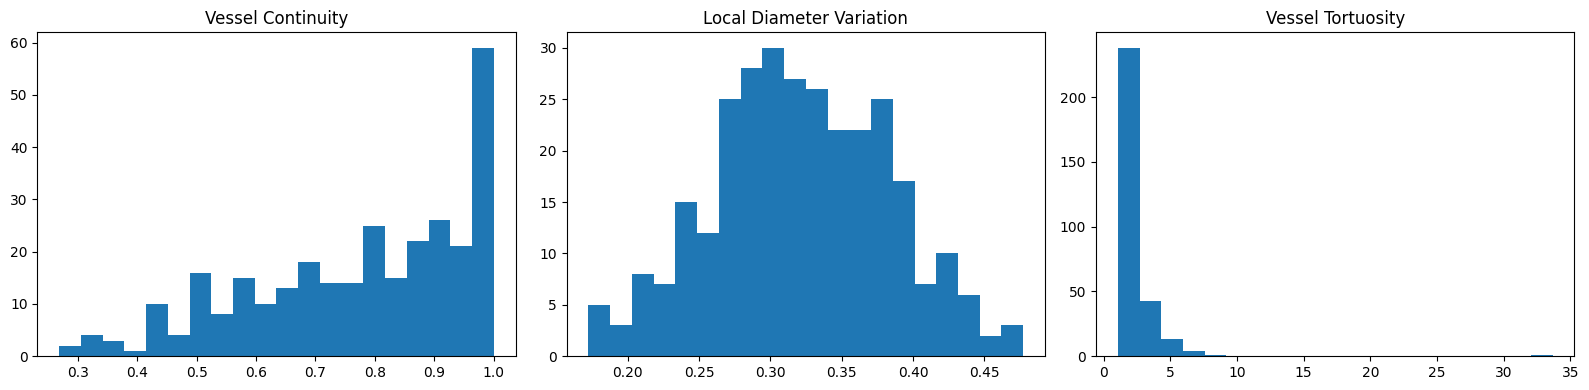

In [14]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(
    continuity_df["continuity_ratio"].dropna(),
    bins=20
)
axes[0].set_title("Vessel Continuity")

axes[1].hist(
    continuity_df["diameter_variation"].dropna(),
    bins=20
)
axes[1].set_title("Local Diameter Variation")

axes[2].hist(
    continuity_df["tortuosity"].dropna(),
    bins=20
)
axes[2].set_title("Vessel Tortuosity")

plt.tight_layout()
plt.show()

###Model Performance Comparison

,Model,Best_Validation_Dice,Dice_Percentage
0,U-Net,0.764902,76.4902
1,Attention U-Net,0.763332,76.3332


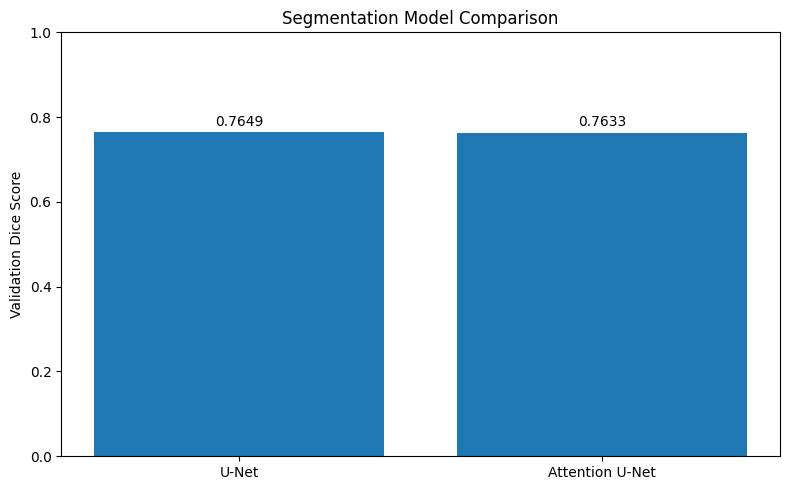

Model comparison report saved!


In [16]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Actual best validation Dice from your training logs
model_results = pd.DataFrame({
    "Model": ["U-Net", "Attention U-Net"],
    "Best_Validation_Dice": [
        0.764902,
        0.763332
    ]
})

model_results["Dice_Percentage"] = (
    model_results["Best_Validation_Dice"] * 100
)

display(model_results)

# Save comparison report
model_results.to_csv(
    VESSEL_DIR / "model_comparison.csv",
    index=False
)

# Visualization
plt.figure(figsize=(8, 5))

plt.bar(
    model_results["Model"],
    model_results["Best_Validation_Dice"]
)

plt.ylim(0, 1)
plt.ylabel("Validation Dice Score")
plt.title("Segmentation Model Comparison")

for i, score in enumerate(
    model_results["Best_Validation_Dice"]
):
    plt.text(i, score + 0.015, f"{score:.4f}",
             ha="center")

plt.tight_layout()

plt.savefig(
    VESSEL_DIR / "model_comparison.png",
    dpi=300
)

plt.show()

print("Model comparison report saved!")

###Milestone 2 Final Report

In [17]:
import json

report = {
    "milestone": "Milestone 2",
    "module": "Artery Segmentation and Vessel Analysis",
    "total_masks_processed": len(mask_files),
    "total_centerlines_generated": len(skeleton_files),
    "total_branch_analysis": len(branch_df),
    "total_vessel_measurements": len(measurement_df),
    "continuity_analysis": len(continuity_df),
    "models_compared": ["U-Net", "Attention U-Net"],
    "outputs": [
        "branch_analysis.csv",
        "vessel_measurements.csv",
        "vessel_analysis_summary.csv",
        "continuity_tortuosity_analysis.csv",
        "model_comparison.csv",
        "model_comparison.png"
    ]
}

with open(
    VESSEL_DIR / "milestone2_final_report.json",
    "w"
) as f:
    json.dump(report, f, indent=4)

print("Milestone 2 report generated!")
print(VESSEL_DIR)

Milestone 2 report generated!
/content/drive/MyDrive/ArteryAI/Milestone-2/outputs/vessel_analysis
